#### 1. Build a list of dataframe from loose csv files in folder and combine

In [11]:
import glob
import pandas as pandas

csv_folder = "../data/loose_csv/*.csv"
file_paths = glob.glob(csv_folder)

print(f"Found {len(file_paths)} files")

dataframe_list = [pandas.read_csv(file) for file in file_paths]
dataframe_combined = pandas.concat(dataframe_list, ignore_index=True)
dataframe_combined = dataframe_combined.reset_index(drop=True)
dataframe_combined.dropna()

Found 15 files


,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Attack Name,Label
0,34.173.20.6-192.168.137.234-443-58644-6,34.173.20.6,443,192.168.137.234,58644,6,14/09/2023 09:24:26 AM,14746364,6,0,...,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic,0
1,34.173.20.6-192.168.137.234-443-58646-6,34.173.20.6,443,192.168.137.234,58646,6,14/09/2023 09:24:41 AM,60102110,18,0,...,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic,0
2,52.40.210.103-192.168.137.40-18665-60378-6,52.40.210.103,18665,192.168.137.40,60378,6,14/09/2023 09:24:14 AM,90106769,9,0,...,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic,0
3,10.0.0.3-10.0.0.254-44505-1883-6,10.0.0.3,44505,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998980,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0
4,10.0.0.7-10.0.0.254-45727-1883-6,10.0.0.7,45727,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998539,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385308,192.168.137.250-192.168.137.156-1883-58194-6,192.168.137.250,1883,192.168.137.156,58194,6,29/08/2023 05:05:46 PM,0,2,0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,1
3385309,192.168.137.250-192.168.137.156-1883-58232-6,192.168.137.250,1883,192.168.137.156,58232,6,29/08/2023 05:05:46 PM,1552,2,0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,1
3385310,192.168.137.250-192.168.137.156-1883-58202-6,192.168.137.250,1883,192.168.137.156,58202,6,29/08/2023 05:05:46 PM,22717,2,0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,1
3385311,192.168.137.250-192.168.137.156-1883-58206-6,192.168.137.250,1883,192.168.137.156,58206,6,29/08/2023 05:05:46 PM,0,2,0,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,MQTT DDoS Publish Flood,1


#### 1a. Filter or combine problem attack targets

In [12]:
dataframe_filtered_rps = dataframe_combined[dataframe_combined['Attack Name'] != 'Recon Ping Sweep']
dataframe_filtered = dataframe_filtered_rps[dataframe_filtered_rps['Attack Name'] != 'MITM ARP Spoofing'].copy()

attack_mapping = {
    'DDoS UDP Flood': 'UDP Flood',
    'DoS UDP Flood': 'UDP Flood',
    'DDoS ICMP Flood': 'ICMP Flood',
    'DoS ICMP Flood': 'ICMP Flood',
    'Recon OS Scan': 'Recon Scan',
    'Recon Port Scan': 'Recon Scan',
    'Recon Vulnerability Scan': 'Recon Scan'
}

dataframe_filtered['Attack Name'] = dataframe_filtered['Attack Name'].replace(attack_mapping)

#### 2. Create a small dataframe for building model by grouping by Attack Name

In [13]:
def sample_or_take_all(group):
    sample_size = min(len(group), 1000)
    return group.sample(n=sample_size, random_state=42)

small_df = dataframe_filtered.groupby('Attack Name').apply(sample_or_take_all)
small_df = small_df.reset_index(level=0)

print(small_df.shape)
print(small_df.head())

(8953, 85)
          Attack Name                                   Flow ID  \
6528   Benign Traffic   192.168.137.234-34.173.20.6-55840-443-6   
26781  Benign Traffic          10.0.0.6-10.0.0.254-38889-1883-6   
6594   Benign Traffic         10.0.0.11-10.0.0.254-40489-1883-6   
4932   Benign Traffic  35.83.169.32-192.168.137.210-443-50650-6   
24854  Benign Traffic          10.0.0.3-10.0.0.254-44505-1883-6   

                Src IP  Src Port           Dst IP  Dst Port  Protocol  \
6528   192.168.137.234     55840      34.173.20.6       443         6   
26781         10.0.0.6     38889       10.0.0.254      1883         6   
6594         10.0.0.11     40489       10.0.0.254      1883         6   
4932      35.83.169.32       443  192.168.137.210     50650         6   
24854         10.0.0.3     44505       10.0.0.254      1883         6   

                    Timestamp  Flow Duration  Total Fwd Packet  ...  \
6528   13/09/2023 12:24:22 PM       60363476                17  ...   
26781

In [ ]:
small_df['Attack Name'].value_counts()

In [ ]:
small_df.columns

#### 2a. Different small dataframe

In [ ]:
def sample_or_take_all(group):
    sample_size = min(len(group), 1000)
    return group.sample(n=sample_size, random_state=42)

small_df_not_filtered = dataframe_combined.groupby('Attack Name').apply(sample_or_take_all)
small_df_not_filtered = small_df_not_filtered.reset_index(level=0)

#### 3. Prepare Dataframe for SVM training

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
import numpy as numpy

# Separate target from features
targets = small_df['Attack Name']
features = small_df.select_dtypes(include=[numpy.number])

# Divide training and testing
features_train, features_test, target_train, target_test = train_test_split(features, targets, test_size=0.2, random_state=42, stratify=targets)

#### 3a. Drop constant values

In [15]:
from sklearn.feature_selection import VarianceThreshold

var_selector = VarianceThreshold(threshold=0.0)

features_train_clean = var_selector.fit_transform(features_train)
features_test_clean = var_selector.transform(features_test)

print(f"Features before: {features_train.shape[1]}")
print(f"Features after removing constants: {features_train_clean.shape[1]}")

Features before: 80
Features after removing constants: 74


#### 4. Apply Scaler

In [16]:
# Scale features
scaler = StandardScaler()
features_train_scaled = scaler.fit_transform(features_train_clean)
features_test_scaled = scaler.transform(features_test_clean)

#### 4a. Apply Selector

In [17]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k=60)
features_train_kbest = selector.fit_transform(features_train_scaled, target_train)
features_test_kbest = selector.transform(features_test_scaled)

print(f"Reduced feature space from {features_train.shape[1]} down to: {features_train_kbest.shape[1]}")

Reduced feature space from 80 down to: 60


#### 5. Train Model

In [18]:
# Initialize LinearSVC
# svc = SVC(kernel='poly', degree=3, gamma='scale', C=1.0, class_weight='balanced', random_state=42)

# Train model
# svc.fit(features_train_scaled, target_train)

svc = SVC(kernel='rbf', gamma='scale', C=20.0, class_weight='balanced', random_state=42)
svc.fit(features_train_kbest, target_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",20.0
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",'balanced'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200


#### 6. Support Vectors

In [19]:
# Total number of support vectors across all classes
print(f"Total Support Vectors: {svc.support_vectors_.shape[0]}")

# Number of support vectors per class
for i, class_name in enumerate(svc.classes_):
    print(f"Class '{class_name}': {svc.n_support_[i]} support vectors")

Total Support Vectors: 2765
Class 'Benign Traffic': 117 support vectors
Class 'DoS TCP Flood': 51 support vectors
Class 'ICMP Flood': 705 support vectors
Class 'MQTT DDoS Publish Flood': 128 support vectors
Class 'MQTT DoS Connect Flood': 363 support vectors
Class 'MQTT DoS Publish Flood': 268 support vectors
Class 'MQTT Malformed': 388 support vectors
Class 'Recon Scan': 23 support vectors
Class 'UDP Flood': 722 support vectors


#### 7. Model Evaluation

In [20]:
# Evaluate the model
target_prediction = svc.predict(features_test_kbest)
print(f"Accuracy score: {accuracy_score(target_test, target_prediction):.4f}")
print("Classification Report:")
print(classification_report(target_test, target_prediction, zero_division=0))

Accuracy score: 0.8113
Classification Report:
                         precision    recall  f1-score   support

         Benign Traffic       1.00      1.00      1.00       200
          DoS TCP Flood       1.00      1.00      1.00       200
             ICMP Flood       0.46      0.75      0.57       200
MQTT DDoS Publish Flood       0.96      0.98      0.97       200
 MQTT DoS Connect Flood       0.90      0.66      0.76       200
 MQTT DoS Publish Flood       0.94      0.72      0.81       191
         MQTT Malformed       0.72      0.81      0.77       200
             Recon Scan       1.00      1.00      1.00       200
              UDP Flood       0.52      0.38      0.44       200

               accuracy                           0.81      1791
              macro avg       0.83      0.81      0.81      1791
           weighted avg       0.83      0.81      0.81      1791



#### 8. Confusion Matrix

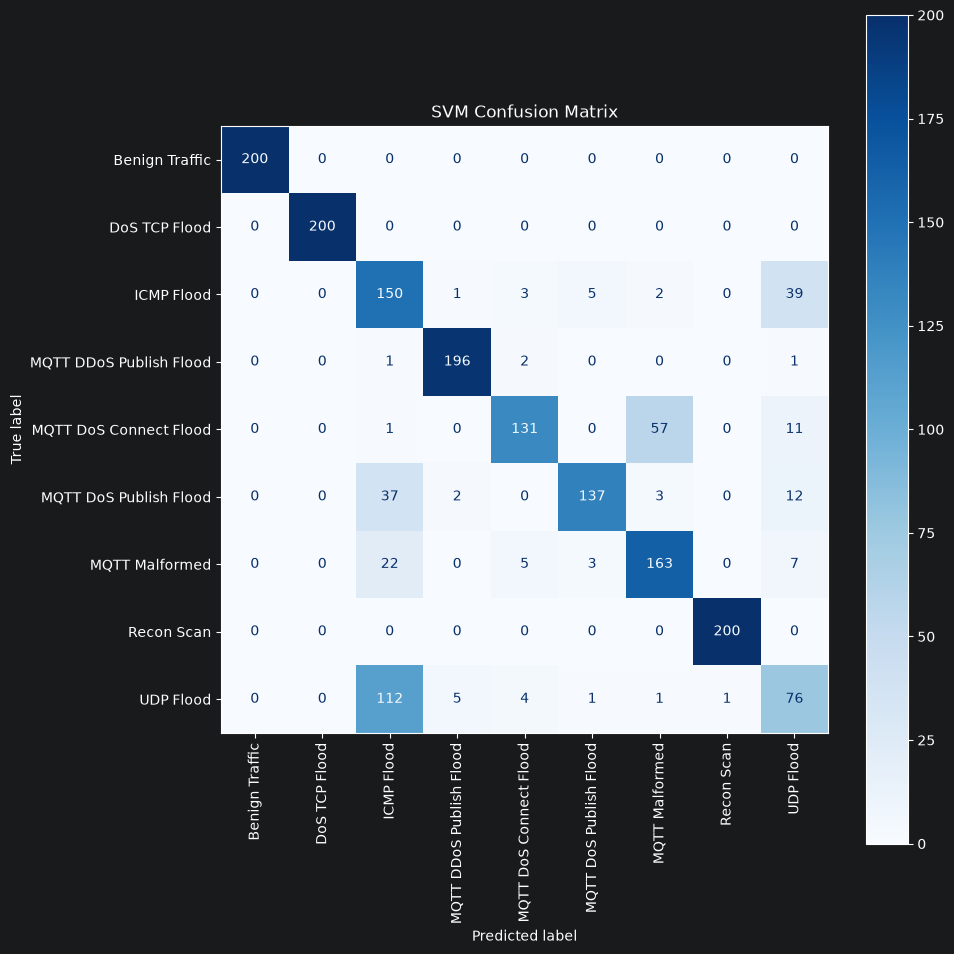

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(target_test, target_prediction)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=svc.classes_)
disp.plot(ax=ax, xticks_rotation='vertical', cmap=plt.cm.Blues)
plt.title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()